# Giai đoạn 4b: so sánh xử lý mất cân bằng
Chỉ dùng train_idx và cùng một StratifiedKFold 5 fold. Không đọc test_idx.

In [1]:
# Nạp dữ liệu và kết quả tuning đã chốt
import sys, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict, validation_curve
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
from imblearn.over_sampling import SMOTE
sys.path.insert(0,str(Path('..').resolve()))
from src.data_prep import load_data, clean_data, get_feature_sets
from src.pipeline import make_pipeline
from src.evaluate import evaluate_cv
from src.logger import log_run
RANDOM_STATE=42; CV=5
df,_=clean_data(load_data(Path('../data/RT_IOT2022'))); sets=get_feature_sets(df); features=sets['NO_SRC_PORT']; X=df.drop(columns=['Attack_type']); y=df['Attack_type']
train_idx=np.sort(np.load('../experiments/split_indices.npz')['train_idx']); X_train=X.iloc[train_idx]; y_train=y.iloc[train_idx]
cv=StratifiedKFold(n_splits=CV,shuffle=True,random_state=RANDOM_STATE)
rf_params={'n_estimators':250,'max_depth':50,'min_samples_split':5,'min_samples_leaf':1,'max_features':None}
dt_params={'criterion':'entropy','max_depth':50,'min_samples_split':5,'min_samples_leaf':2}
print(f'Train={len(X_train)} dòng; chỉ dùng train_idx; CV={CV} fold.')

Train=94337 dòng; chỉ dùng train_idx; CV=5 fold.


Dùng lại tham số tốt nhất đã tìm được, không chạy lại RandomizedSearchCV. Tất cả cấu hình dưới đây dùng chung đối tượng `cv`.

In [2]:
# Tạo pipeline cho bốn cách xử lý mất cân bằng
counts=y_train.value_counts(); minority_500={c:500 for c,n in counts.items() if n<500}; minority_200={c:200 for c,n in counts.items() if n<200}
def rf_pipe(method):
    model=RandomForestClassifier(**rf_params,random_state=RANDOM_STATE,n_jobs=-1)
    if method=='none': return make_pipeline(model,features,random_state=RANDOM_STATE)
    if method=='balanced': return make_pipeline(RandomForestClassifier(**rf_params,class_weight='balanced',random_state=RANDOM_STATE,n_jobs=-1),features,random_state=RANDOM_STATE)
    target=minority_500 if method=='SMOTE_500' else minority_200
    return make_pipeline(model,features,sampler='smote',k_neighbors=3,sampling_strategy=target,random_state=RANDOM_STATE)
pipes={m:rf_pipe(m) for m in ['none','balanced','SMOTE_500','SMOTE_200']}
# Kiểm tra SMOTE trên một fold sau preprocessing
tr,va=next(cv.split(X_train,y_train)); pre=pipes['SMOTE_500'].named_steps['preprocess']; Xt=pre.fit_transform(X_train.iloc[tr][features],y_train.iloc[tr]); sm=SMOTE(k_neighbors=3,sampling_strategy=minority_500,random_state=42); _,ys=sm.fit_resample(Xt,y_train.iloc[tr]); print('Trước:',y_train.iloc[tr].value_counts().sort_index().to_dict()); print('Sau:',pd.Series(ys).value_counts().sort_index().to_dict())
assert all(pd.Series(ys).value_counts().get(c,0)>=500 for c in minority_500), 'SMOTE không nâng lớp hiếm lên 500.'

Trước: {'ARP_poisioning': 4880, 'DDOS_Slowloris': 341, 'DOS_SYN_Hping': 57657, 'MQTT_Publish': 2651, 'Metasploit_Brute_Force_SSH': 23, 'NMAP_FIN_SCAN': 18, 'NMAP_OS_DETECTION': 1280, 'NMAP_TCP_scan': 641, 'NMAP_UDP_SCAN': 1654, 'NMAP_XMAS_TREE_SCAN': 1286, 'Thing_Speak': 4898, 'Wipro_bulb': 140}
Sau: {'ARP_poisioning': 4880, 'DDOS_Slowloris': 500, 'DOS_SYN_Hping': 57657, 'MQTT_Publish': 2651, 'Metasploit_Brute_Force_SSH': 500, 'NMAP_FIN_SCAN': 500, 'NMAP_OS_DETECTION': 1280, 'NMAP_TCP_scan': 641, 'NMAP_UDP_SCAN': 1654, 'NMAP_XMAS_TREE_SCAN': 1286, 'Thing_Speak': 4898, 'Wipro_bulb': 500}


SMOTE được kiểm tra trên phần train của fold đầu tiên sau bước mã hóa. Các lớp dưới 500 phải đạt đúng mục tiêu 500; test không tham gia.

In [3]:
# Đánh giá và ghi log hai cấu hình SMOTE mới
results={}; recalls={}; preds={}
for name,pipe,method in [('RF_none',pipes['none'],'none'),('RF_balanced',pipes['balanced'],'class_weight_balanced'),('RF_SMOTE_500',pipes['SMOTE_500'],'SMOTE_500'),('RF_SMOTE_200',pipes['SMOTE_200'],'SMOTE_200')]:
    start=time.perf_counter(); r=evaluate_cv(pipe,X_train[features],y_train,random_state=42,n_splits=5); elapsed=time.perf_counter()-start; results[name]=r; recalls[name]=r['recall_by_class']; preds[name]=r['predictions']; log_run(name,'NO_SRC_PORT',5,r,params=f'n_estimators=250;max_depth=50;min_samples_split=5;sampling={method};k=3' if 'SMOTE' in name else f'n_estimators=250;max_depth=50;min_samples_split=5;sampling={method}',notes=f'thời gian chạy={elapsed:.2f} giây; chỉ CV trên train',stage=4,imbalance_method=method)
display(pd.DataFrame({k:{'Macro-F1':v['macro_f1_mean'],'Std':v['macro_f1_std'],'Balanced accuracy':v['balanced_acc_mean'],'MCC':v['mcc_mean']} for k,v in results.items()}).T)

,Macro-F1,Std,Balanced accuracy,MCC
RF_none,0.957256,0.013339,0.946346,0.993335
RF_balanced,0.934649,0.014152,0.950992,0.992290
RF_SMOTE_500,0.954276,0.009847,0.950480,0.993753
RF_SMOTE_200,0.951249,0.019030,0.947998,0.993492


Đã chạy thêm SMOTE_500 và SMOTE_200. Các lần chạy được ghi log với params ngắn; kết quả cũ của RF_none và RF_balanced chỉ dùng lại trong so sánh, không ghi trùng.

In [4]:
# So sánh Macro-F1 từng fold bằng cùng các fold
from sklearn.base import clone
fold_scores={}; fold_pipes={'RF_none':pipes['none'],'RF_balanced':pipes['balanced'],'RF_SMOTE_500':pipes['SMOTE_500'],'RF_SMOTE_200':pipes['SMOTE_200'],'DT_tuned':make_pipeline(DecisionTreeClassifier(**dt_params,random_state=42),features,random_state=42),'RF_tuned':make_pipeline(RandomForestClassifier(**rf_params,random_state=42,n_jobs=-1),features,random_state=42)}
for name,pipe in fold_pipes.items():
    vals=[]
    for tr,va in cv.split(X_train,y_train):
        p=clone(pipe); p.fit(X_train.iloc[tr][features],y_train.iloc[tr]); vals.append(__import__('sklearn.metrics',fromlist=['f1_score']).f1_score(y_train.iloc[va],p.predict(X_train.iloc[va][features]),average='macro'))
    fold_scores[name]=np.array(vals)
fold_table=pd.DataFrame(fold_scores,index=[f'Fold {i}' for i in range(1,6)]); display(fold_table)
pairs=[('RF_tuned','DT_tuned'),('RF_balanced','RF_none'),('RF_SMOTE_500','RF_none'),('RF_SMOTE_200','RF_none')]
for a,b in pairs:
    d=fold_table[a]-fold_table[b]; print(f'{a} - {b}: mean={d.mean():.6f}, std={d.std():.6f}, thắng {int((d>0).sum())}/5 fold')

,RF_none,RF_balanced,RF_SMOTE_500,RF_SMOTE_200,DT_tuned,RF_tuned
Fold 1,0.967056,0.937074,0.968058,0.978780,0.953949,0.967056
Fold 2,0.944065,0.907600,0.945220,0.921962,0.931386,0.944065
Fold 3,0.966162,0.944912,0.962708,0.957514,0.964901,0.966162
Fold 4,0.938294,0.936562,0.942443,0.940462,0.942628,0.938294
Fold 5,0.970700,0.947095,0.952950,0.957527,0.950617,0.970700


RF_tuned - DT_tuned: mean=0.008559, std=0.009873, thắng 4/5 fold
RF_balanced - RF_none: mean=-0.022607, std=0.013087, thắng 0/5 fold
RF_SMOTE_500 - RF_none: mean=-0.002980, std=0.008691, thắng 3/5 fold
RF_SMOTE_200 - RF_none: mean=-0.006006, std=0.013216, thắng 2/5 fold


Bảng và hiệu số được tính theo từng fold, giúp biết chênh lệch trung bình có ổn định hay chỉ do một fold.

In [5]:
# Recall, precision và F1 cho bốn lớp hiếm
rare=['Wipro_bulb','DDOS_Slowloris','Metasploit_Brute_Force_SSH','NMAP_FIN_SCAN']; rows=[]
for method,pipe in [('none',pipes['none']),('balanced',pipes['balanced']),('SMOTE_500',pipes['SMOTE_500']),('SMOTE_200',pipes['SMOTE_200'])]:
    pred=preds.get('RF_'+method); yt=y_train.to_numpy(); pr,rc,f1,_=precision_recall_fscore_support(yt,pred,labels=rare,zero_division=0)
    for c,p,r,f in zip(rare,pr,rc,f1): rows.append({'method':method,'class':c,'precision':p,'recall':r,'f1':f})
rare_table=pd.DataFrame(rows); display(rare_table); mean_recall=rare_table.pivot(index='class',columns='method',values='recall').mean(axis=0); print('Recall trung bình theo cách:',mean_recall.to_dict()); print('Cách cao nhất:',mean_recall.idxmax(),mean_recall.max())

,method,class,precision,recall,f1
0,none,Wipro_bulb,0.962963,0.891429,0.925816
1,none,DDOS_Slowloris,0.928058,0.908451,0.918149
2,none,Metasploit_Brute_Force_SSH,0.884615,0.793103,0.836364
3,none,NMAP_FIN_SCAN,0.947368,0.818182,0.878049
4,balanced,Wipro_bulb,0.937853,0.948571,0.943182
5,balanced,DDOS_Slowloris,0.903226,0.920188,0.911628
6,balanced,Metasploit_Brute_Force_SSH,0.605263,0.793103,0.686567
7,balanced,NMAP_FIN_SCAN,0.666667,0.818182,0.734694
8,SMOTE_500,Wipro_bulb,0.964497,0.931429,0.947674
9,SMOTE_500,DDOS_Slowloris,0.918033,0.920188,0.919109


Recall trung bình theo cách: {'SMOTE_200': 0.8576637042737092, 'SMOTE_500': 0.8657254078283705, 'balanced': 0.8700111221140847, 'none': 0.852791135527901}
Cách cao nhất: balanced 0.8700111221140847


Recall, precision và F1 được tính từ dự đoán out-of-fold. Trung bình recall dùng `axis=0`, nên tên trả về là tên cách xử lý.

In [6]:
# Top 10 cặp nhầm RF tuned và lỗi nhị phân
rf_pred=preds.get('RF_tuned');
if rf_pred is None: rf_pred=cross_val_predict(fold_pipes['RF_tuned'],X_train[features],y_train,cv=cv,n_jobs=-1)
normal={'Thing_Speak','MQTT_Publish','Wipro_bulb'}; flat=pd.DataFrame({'true':y_train.to_numpy(),'pred':rf_pred}); errors=flat[flat.true!=flat.pred].groupby(['true','pred']).size().reset_index(name='count').sort_values('count',ascending=False).head(10); display(errors)
attack_to_normal=((~flat.true.isin(normal))&flat.pred.isin(normal)).sum(); normal_to_attack=(flat.true.isin(normal)&(~flat.pred.isin(normal))).sum(); attack_total=(~flat.true.isin(normal)).sum(); print(pd.DataFrame({'error_type':['attack -> normal','normal -> attack'],'count':[attack_to_normal,normal_to_attack],'rate':[attack_to_normal/attack_total,normal_to_attack/flat.true.isin(normal).sum()]}))

,true,pred,count
3,ARP_poisioning,Thing_Speak,54
24,Thing_Speak,ARP_poisioning,52
6,DDOS_Slowloris,NMAP_UDP_SCAN,33
17,NMAP_UDP_SCAN,DDOS_Slowloris,28
16,NMAP_UDP_SCAN,ARP_poisioning,14
34,Wipro_bulb,Thing_Speak,13
11,Metasploit_Brute_Force_SSH,ARP_poisioning,6
20,NMAP_UDP_SCAN,Thing_Speak,6
28,Thing_Speak,NMAP_UDP_SCAN,5
30,Thing_Speak,Wipro_bulb,5


         error_type  count      rate
0  attack -> normal     64  0.000755
1  normal -> attack     69  0.007179


Các cặp nhầm được làm phẳng thành DataFrame rồi `reset_index`, nên nhãn thật và nhãn dự đoán luôn hiện rõ. Tỷ lệ tấn công thành bình thường dùng tổng số mẫu tấn công trong train.

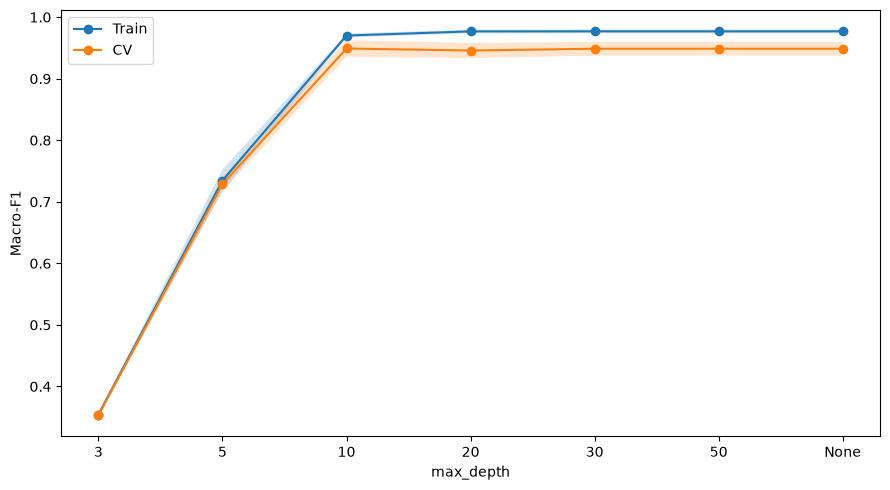

In [8]:
# Vẽ validation curve max_depth theo thứ tự số
depths=[3,5,10,20,30,50,None]; model=make_pipeline(DecisionTreeClassifier(min_samples_split=5,min_samples_leaf=2,criterion='entropy',random_state=42),features,random_state=42)
train_sc,cv_sc=validation_curve(model,X_train[features],y_train,param_name='model__max_depth',param_range=depths,cv=cv,scoring='f1_macro',n_jobs=-1); x=np.arange(len(depths)); plt.figure(figsize=(9,5)); plt.plot(x,train_sc.mean(axis=1),marker='o',label='Train'); plt.fill_between(x,train_sc.mean(axis=1)-train_sc.std(axis=1),train_sc.mean(axis=1)+train_sc.std(axis=1),alpha=.2); plt.plot(x,cv_sc.mean(axis=1),marker='o',label='CV'); plt.fill_between(x,cv_sc.mean(axis=1)-cv_sc.std(axis=1),cv_sc.mean(axis=1)+cv_sc.std(axis=1),alpha=.2); plt.xticks(x,[str(d) for d in depths]); plt.xlabel('max_depth'); plt.ylabel('Macro-F1'); plt.legend(); plt.tight_layout(); plt.savefig('../figures/dt_max_depth_curve_v2.png',dpi=150); plt.show()

Đường cong dùng đúng thứ tự max_depth yêu cầu và có vùng ± độ lệch chuẩn cho train/CV.

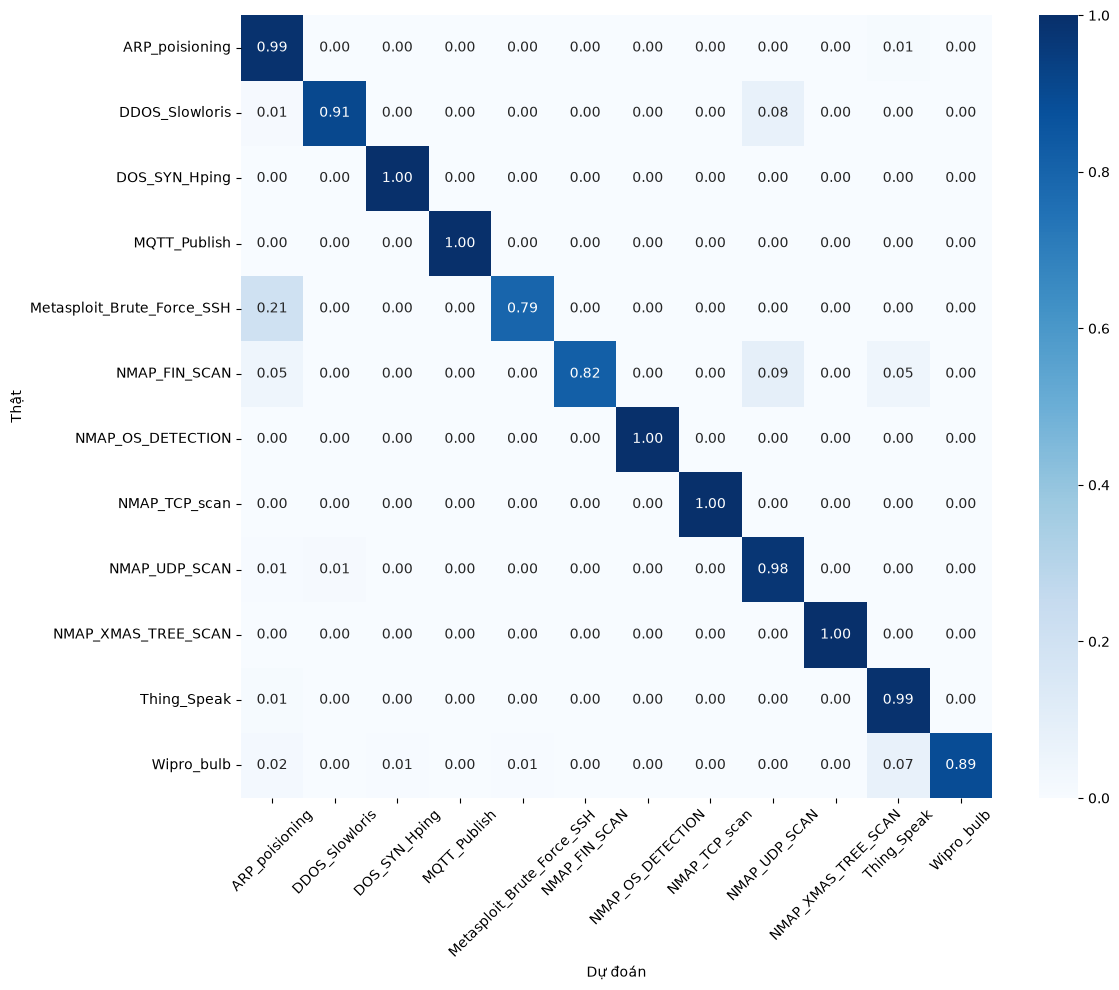

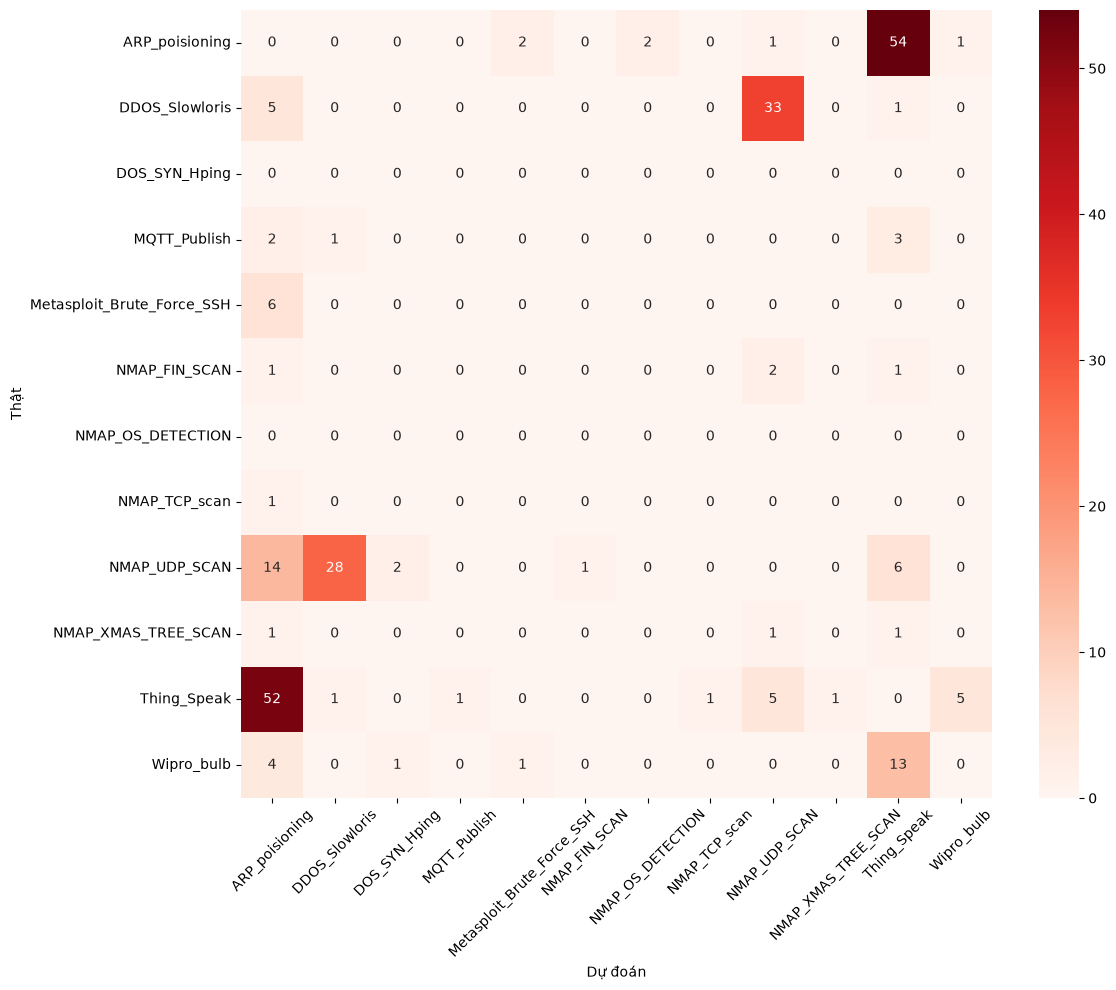

In [9]:
# Vẽ confusion matrix chuẩn hóa và ma trận lỗi
labels=sorted(y_train.unique()); cm=confusion_matrix(y_train,rf_pred,labels=labels); norm=cm/cm.sum(axis=1,keepdims=True); fig,ax=plt.subplots(figsize=(12,10)); sns.heatmap(norm,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='Blues',xticklabels=labels,yticklabels=labels,ax=ax); ax.tick_params(axis='x',rotation=45); ax.tick_params(axis='y',rotation=0); ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thật'); plt.tight_layout(); plt.savefig('../figures/rf_tuned_confusion_normalized_v2.png',dpi=150); plt.show()
err=cm.copy(); np.fill_diagonal(err,0); fig,ax=plt.subplots(figsize=(12,10)); sns.heatmap(err,annot=True,fmt='d',cmap='Reds',xticklabels=labels,yticklabels=labels,ax=ax); ax.tick_params(axis='x',rotation=45); ax.tick_params(axis='y',rotation=0); ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thật'); plt.tight_layout(); plt.savefig('../figures/rf_tuned_confusion_errors_v2.png',dpi=150); plt.show()

Hai hình cuối lần lượt cho recall từng lớp và số lỗi ngoài đường chéo của RF tuned, đều dựa trên dự đoán out-of-fold.

In [10]:
# Tổng kết 4b bằng số liệu đã tính
best_method=max(results,key=lambda k:results[k]['macro_f1_mean']); rare_method=mean_recall.idxmax(); d=fold_table['RF_tuned']-fold_table['DT_tuned']; top10=errors[['true','pred','count']].to_dict('records'); print('=== TỔNG KẾT GIAI ĐOẠN 4b ==='); print(f'(a) Macro-F1 cao nhất: {best_method}, {results[best_method]["macro_f1_mean"]:.6f} ± {results[best_method]["macro_f1_std"]:.6f}.'); print(f'(b) Recall trung bình lớp hiếm cao nhất: {rare_method}, {mean_recall[rare_method]:.6f}.'); print(f'(c) RF tuned - DT tuned: mean={d.mean():.6f}, std={d.std():.6f}, thắng {(d>0).sum()}/5 fold; ổn định={bool((d>0).sum()>=4)}.'); print(f'(d) Tỷ lệ tấn công bị nhầm thành bình thường: {attack_to_normal}/{attack_total}={attack_to_normal/attack_total:.6f}. Top 10:'); print(top10); print('(e) Đề xuất Giai đoạn 5: dùng RF tuned với cấu hình đã chốt và cách xử lý có Macro-F1 CV cao nhất; chỉ đánh giá test một lần, vì lựa chọn dựa trên CV train.')

=== TỔNG KẾT GIAI ĐOẠN 4b ===
(a) Macro-F1 cao nhất: RF_none, 0.957256 ± 0.013339.
(b) Recall trung bình lớp hiếm cao nhất: balanced, 0.870011.
(c) RF tuned - DT tuned: mean=0.008559, std=0.009873, thắng 4/5 fold; ổn định=True.
(d) Tỷ lệ tấn công bị nhầm thành bình thường: 64/84725=0.000755. Top 10:
[{'true': 'ARP_poisioning', 'pred': 'Thing_Speak', 'count': 54}, {'true': 'Thing_Speak', 'pred': 'ARP_poisioning', 'count': 52}, {'true': 'DDOS_Slowloris', 'pred': 'NMAP_UDP_SCAN', 'count': 33}, {'true': 'NMAP_UDP_SCAN', 'pred': 'DDOS_Slowloris', 'count': 28}, {'true': 'NMAP_UDP_SCAN', 'pred': 'ARP_poisioning', 'count': 14}, {'true': 'Wipro_bulb', 'pred': 'Thing_Speak', 'count': 13}, {'true': 'Metasploit_Brute_Force_SSH', 'pred': 'ARP_poisioning', 'count': 6}, {'true': 'NMAP_UDP_SCAN', 'pred': 'Thing_Speak', 'count': 6}, {'true': 'Thing_Speak', 'pred': 'NMAP_UDP_SCAN', 'count': 5}, {'true': 'Thing_Speak', 'pred': 'Wipro_bulb', 'count': 5}]
(e) Đề xuất Giai đoạn 5: dùng RF tuned với cấu hình